# Order-book volatility forecasting

Predict next-window volatility from the first two levels of the order book. The comparison uses a persistence baseline, weighted regression and LightGBM on five Optiver stocks.

In [1]:
import sys
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / "config.json").exists():
    ROOT = ROOT.parent
assert (ROOT / "config.json").exists(), "Run from the repository or notebooks directory."
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from orderbook_volatility.pipeline import run, group_partitions
config = json.loads((ROOT / "config.json").read_text())
display(config)

{'stock_ids': [0, 1, 2, 3, 61],
 'seed': 42,
 'test_fraction': 0.2,
 'validation_fraction': 0.2,
 'threads': 2,
 'source_repo': 'Dr4k3z/realized-vol',
 'source_revision': 'd0d4e8d982bb6f1eaf3127833032c938c8873ede',
 'lightgbm': {'objective': 'regression',
  'n_estimators': 400,
  'learning_rate': 0.03,
  'num_leaves': 15,
  'min_child_samples': 50,
  'reg_lambda': 1.0,
  'verbosity': -1}}

## Data

The book observations cover 600 seconds; the target covers the next 600 seconds. Features summarize WAP returns, spreads, depth and imbalance over the full window and its last 300 seconds.

$$WAP_t = \frac{P_t^{bid}Q_t^{ask}+P_t^{ask}Q_t^{bid}}{Q_t^{bid}+Q_t^{ask}},\qquad RV = \sqrt{\sum_t (\Delta\log WAP_t)^2}. $$

In [2]:
metadata = run(ROOT)
display({k: metadata[k] for k in ["observations", "stocks", "time_buckets", "split_rows", "validation"]})

Features: stock 0


Features: stock 1


Features: stock 2


Features: stock 3


Features: stock 61


     split           model    rmspe  rows
validation     persistence 0.312779  3065
validation weighted_linear 0.242193  3065
validation        lightgbm 0.237324  3065
      test     persistence 0.325289  3830
      test weighted_linear 0.236967  3830
      test        lightgbm 0.224393  3830


{'observations': 19150,
 'stocks': 5,
 'time_buckets': 3830,
 'split_rows': {'fit': 12255, 'validation': 3065, 'test': 3830},
 'validation': 'seeded grouped holdout; anonymized time_id is not a chronological timestamp'}

In [3]:
features = pd.read_parquet(ROOT / "artifacts/features.parquet")
display(features[["stock_id", "time_id", "target", "log_return_realized_volatility", "price_spread_mean", "total_volume_mean"]].head(10))

,stock_id,time_id,target,log_return_realized_volatility,price_spread_mean,total_volume_mean
0,0,5,0.004136,0.004499,0.000852,323.496689
1,0,11,0.001445,0.001204,0.000394,411.450000
2,0,16,0.002168,0.002369,0.000725,416.351064
3,0,31,0.002195,0.002574,0.000860,435.266667
4,0,62,0.001747,0.001894,0.000397,343.221591
5,0,72,0.004912,0.007902,0.001637,352.574144
6,0,97,0.009388,0.010034,0.001665,321.081522
7,0,103,0.004120,0.005331,0.001039,324.608844
8,0,109,0.002182,0.001797,0.000445,361.292373
9,0,123,0.002669,0.003273,0.000468,329.837156


## Split

Bucket IDs are anonymized. Every stock in a bucket goes into the same partition: about 64% training, 16% validation and 20% test. The models use fixed settings and fit only on training rows. This is a grouped split, not a chronological one.

In [4]:
parts = group_partitions(features, config)
groups = {name: set(features.iloc[ix].time_id) for name, ix in parts.items()}
assert groups["fit"].isdisjoint(groups["validation"])
assert groups["fit"].isdisjoint(groups["test"])
assert groups["validation"].isdisjoint(groups["test"])
display(pd.DataFrame({name: {"observations": len(ix), "time_buckets": len(groups[name])} for name, ix in parts.items()}).T)

,observations,time_buckets
fit,12255,2451
validation,3065,613
test,3830,766


## Models

Persistence uses the observed-window volatility. The linear regressions use three features and fit separately by stock. LightGBM pools 18 features. Both models use inverse-squared-target training weights. All forecasts receive the same fixed positive floor.

split,test,validation
model,,
lightgbm,0.22439,0.23732
persistence,0.32529,0.31278
weighted_linear,0.23697,0.24219


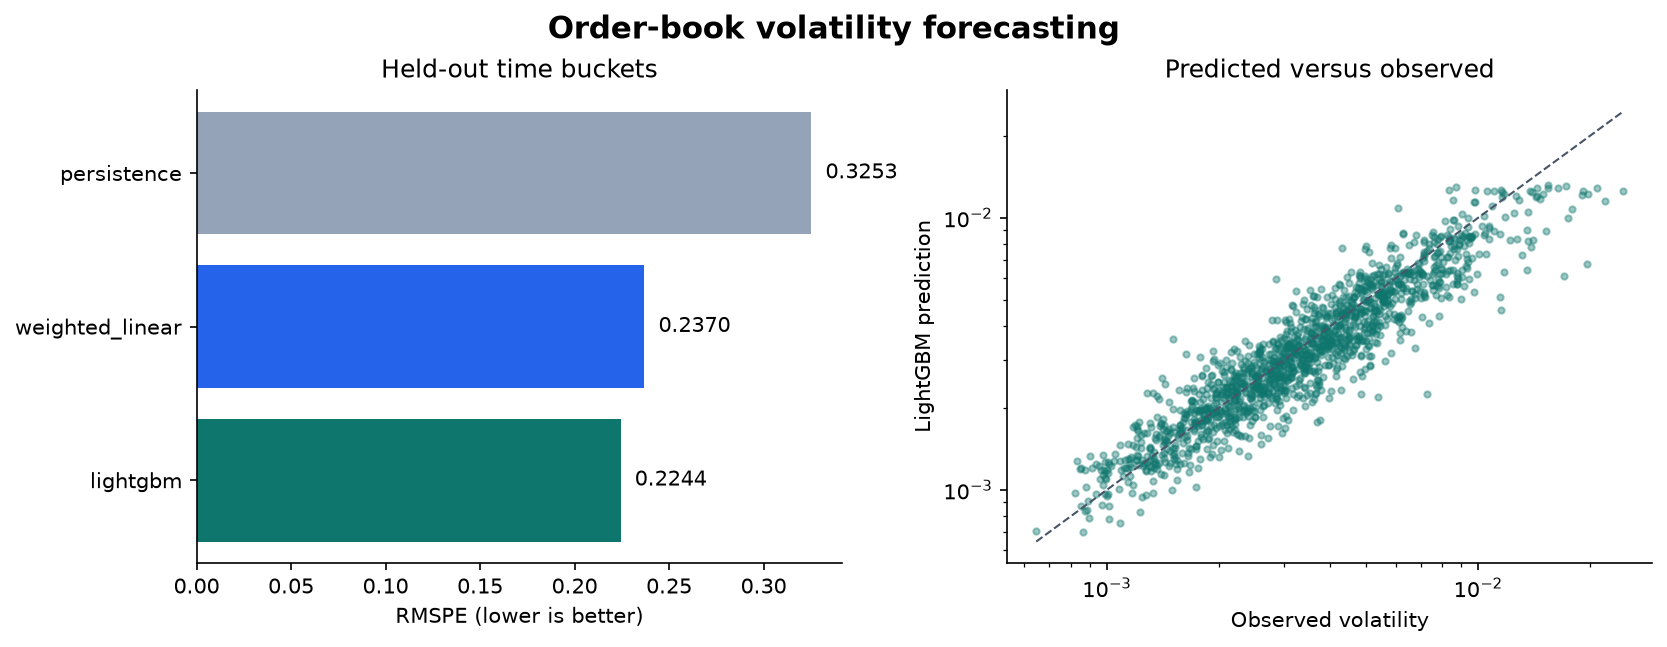

In [5]:
metrics = pd.read_csv(ROOT / "artifacts/metrics.csv")
display(metrics.pivot(index="model", columns="split", values="rmspe").round(5))
display(Image(filename=str(ROOT / "artifacts/overview.png")))

model,lightgbm,persistence,weighted_linear
stock_id,,,
0,0.27253,0.40155,0.28006
1,0.21742,0.31002,0.22825
2,0.21083,0.33890,0.24369
3,0.23854,0.32681,0.24165
61,0.16990,0.22374,0.18017


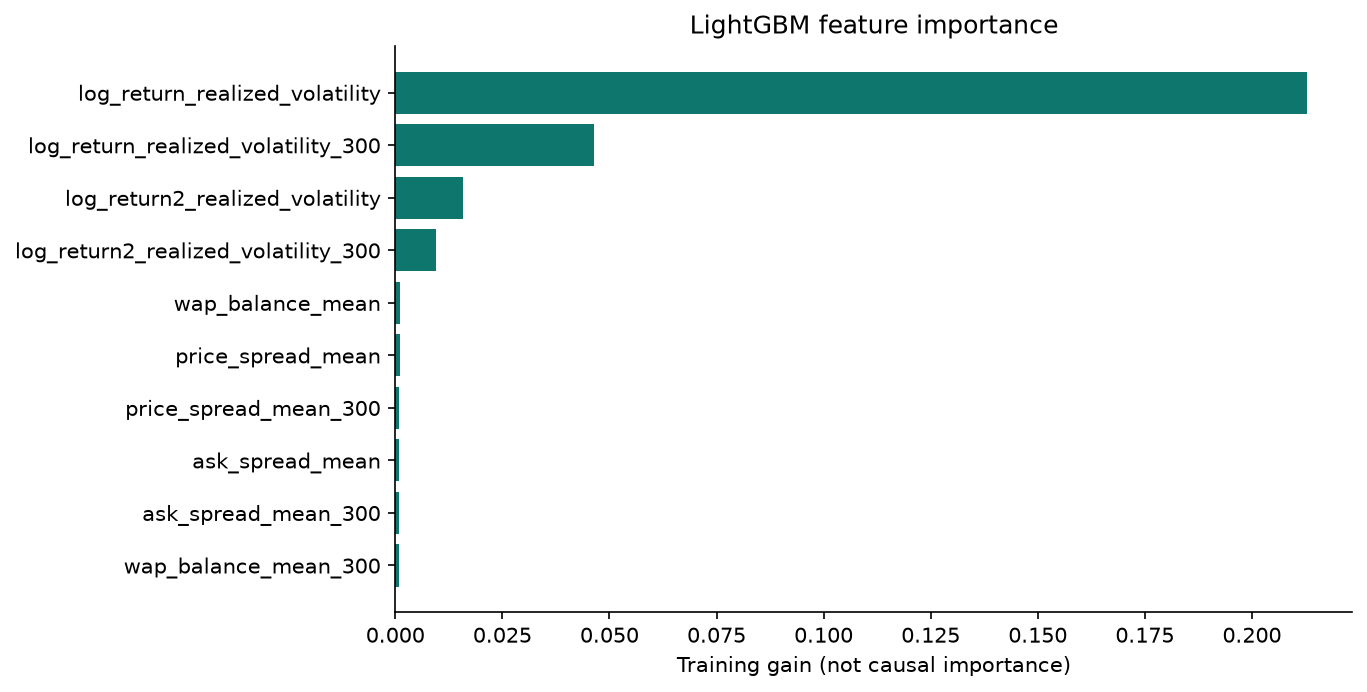

In [6]:
display(pd.read_csv(ROOT / "artifacts/per_stock.csv").pivot(index="stock_id", columns="model", values="rmspe").round(5))
display(Image(filename=str(ROOT / "artifacts/feature_importance.png")))

## Uncertainty

A paired bootstrap resamples complete test buckets, keeping the stocks in each bucket together. Negative differences below mean lower RMSPE than persistence. This accounts for within-bucket dependence, not unknown dependence across buckets or future regimes.

In [7]:
display(pd.read_csv(ROOT / "artifacts/uncertainty.csv").round(5))
test = metrics.query("split == 'test'").set_index("model").rmspe
improvement = 100 * (1 - test["lightgbm"] / test["persistence"])
display(Markdown(f"**Result:** LightGBM RMSPE is {test['lightgbm']:.5f}, compared with {test['persistence']:.5f} for persistence ({improvement:.1f}% lower). This is the supplied five-stock grouped holdout, not a trading return."))

,model,reference,rmspe_difference,lower_95,upper_95,bootstrap_repetitions
0,weighted_linear,persistence,-0.08832,-0.10432,-0.07184,1000
1,lightgbm,persistence,-0.10090,-0.12413,-0.07927,1000


**Result:** LightGBM RMSPE is 0.22439, compared with 0.32529 for persistence (31.0% lower). This is the supplied five-stock grouped holdout, not a trading return.

## Notes

The improvement is measured on a small five-stock sample. It is not a trading return. Feature gain is not causal importance. Raw prices stay local, and the run manifest records source hashes, settings and software versions. Tests check bucket isolation, feature definitions, the metric and independence from test targets.